In [ ]:
import os
import urllib.request
import zipfile
import collections
import string
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence
import torchvision.transforms as transforms
from torchvision.models import vgg16, VGG16_Weights
from PIL import Image
import nltk
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction
import matplotlib.pyplot as plt

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cuda


In [2]:
def download_glove(data_dir='DATASETS'):
    os.makedirs(data_dir, exist_ok=True)
    glove_path = os.path.join(data_dir, 'glove.6B.50d.txt')
    zip_path = os.path.join(data_dir, 'glove.6B.zip')
    
    if not os.path.exists(glove_path):
        print("GloVe embeddings not found. Downloading...")
        url = 'http://nlp.stanford.edu/data/glove.6B.zip'
        urllib.request.urlretrieve(url, zip_path)
        print("Download complete. Extracting...")
        with zipfile.ZipFile(zip_path, 'r') as zip_ref:
            zip_ref.extractall(data_dir)
        print("Extraction complete.")
    else:
        print("GloVe embeddings already exist.")
    return glove_path

glove_file = download_glove('DATASETS')

GloVe embeddings already exist.


In [ ]:
# Paths
DATA_DIR = 'DATASETS/Image captioning dataset'
IMAGES_DIR = os.path.join(DATA_DIR, 'Images/Images')
MAPPING_DIR = os.path.join(DATA_DIR, 'image_mapping and captions')
IMAGE_NAMES_FILE = os.path.join(MAPPING_DIR, 'image_names.txt')
CAPTIONS_FILE = os.path.join(MAPPING_DIR, 'captions.txt')

with open(IMAGE_NAMES_FILE, 'r') as f:
    assigned_images = set([line.strip() for line in f.readlines() if line.strip()])
print(f"Total assigned images: {len(assigned_images)}")

captions_dict = collections.defaultdict(list)
with open(CAPTIONS_FILE, 'r') as f:
    for line in f:
        line = line.strip()
        if not line: continue
        parts = line.split('	')
        if len(parts) == 2:
            img_id = parts[0].split('#')[0]
            caption = parts[1]
            if img_id in assigned_images:
                captions_dict[img_id].append(caption)

print(f"Images with captions after filtering: {len(captions_dict)}")


# TRAIN / VAL / TEST SPLIT (80/10/10)

image_list = list(captions_dict.keys())
np.random.seed(42)
np.random.shuffle(image_list)

train_size = int(0.8 * len(image_list))
val_size = int(0.1 * len(image_list))

train_imgs = image_list[:train_size]
val_imgs = image_list[train_size:train_size+val_size]
test_imgs = image_list[train_size+val_size:]

print(f"Images - Train: {len(train_imgs)}, Val: {len(val_imgs)}, Test: {len(test_imgs)}")



# BUILD VOCABULARY (TRAIN ONLY)

class Vocabulary:
    def __init__(self, freq_threshold=2):
        self.freq_threshold = freq_threshold
        # removed <SOS> to fix looping
        self.word2idx = {"<PAD>": 0, "<EOS>": 1, "<UNK>": 2}
        self.idx2word = {0: "<PAD>", 1: "<EOS>", 2: "<UNK>"}
        self.idx = 3
        
    def __len__(self):
        return len(self.word2idx)
        
    def build_vocabulary(self, sentence_list):
        frequencies = collections.Counter()
        for sentence in sentence_list:
            # removing punctuations
            sentence = sentence.lower().translate(str.maketrans('', '', string.punctuation))
            for word in sentence.split():
                frequencies[word] += 1
                
        for word, count in frequencies.items():
            if count >= self.freq_threshold:
                self.word2idx[word] = self.idx
                self.idx2word[self.idx] = word
                self.idx += 1
                
    def numericalize(self, text):
        tokenized = text.lower().translate(str.maketrans('', '', string.punctuation)).split()
        return [self.word2idx.get(w, self.word2idx["<UNK>"]) for w in tokenized] + [self.word2idx["<EOS>"]]

# extracting captions only from training set images
train_captions = []
for img in train_imgs:
    train_captions.extend(captions_dict[img])

vocab = Vocabulary(freq_threshold=2)
vocab.build_vocabulary(train_captions)
print(f"Vocabulary Size (Train Only!): {len(vocab)}")


Total assigned images: 4000
Images with captions after filtering: 4000
Images - Train: 3200, Val: 400, Test: 400
Vocabulary Size (Train Only!): 3335


In [4]:
def load_glove_embeddings(glove_file, vocab, embed_size=50):
    embeddings_index = {}
    with open(glove_file, 'r', encoding='utf-8') as f:
        for line in f:
            values = line.split()
            word = values[0]
            if word in vocab.word2idx:
                coefs = np.asarray(values[1:], dtype='float32')
                embeddings_index[word] = coefs
                
    embedding_matrix = np.zeros((len(vocab), embed_size))
    for word, i in vocab.word2idx.items():
        if i == 0: continue
        embedding_vector = embeddings_index.get(word)
        if embedding_vector is not None:
            embedding_matrix[i] = embedding_vector
        else:
            embedding_matrix[i] = np.random.normal(scale=0.6, size=(embed_size,))
            
    return torch.tensor(embedding_matrix, dtype=torch.float32)

glove_matrix = load_glove_embeddings(glove_file, vocab, embed_size=50)
print(f"GloVe Matrix Shape: {glove_matrix.shape}")

GloVe Matrix Shape: torch.Size([3335, 50])


In [ ]:
from tqdm import tqdm
import torchvision.transforms as transforms

print("Precomputing VGG16 Features... This will take a few minutes but saves hours of training!")

cache_path = os.path.join(DATA_DIR, 'vgg16_features_cache.pt')
if os.path.exists(cache_path):
    print("Found cache! Loading precomputed VGG16 features instantly...")
    precomputed_features = torch.load(cache_path)
    print(f"Successfully loaded {len(precomputed_features)} features!")
else:
    print("No cache found. Precomputing VGG16 Features...")
    
    transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225))
    ])
    vgg_extractor = vgg16(weights=VGG16_Weights.DEFAULT).to(device)
    vgg_extractor.eval()
    features_net = vgg_extractor.features
    pool_net = nn.AdaptiveAvgPool2d((1,1))
    precomputed_features = {}
    unique_images = list(assigned_images) 
    with torch.no_grad():
        for img_id in tqdm(unique_images):
            img_path = os.path.join(IMAGES_DIR, img_id)
            if not os.path.exists(img_path): continue
                
            img = Image.open(img_path).convert("RGB")
            img_tensor = transform(img).unsqueeze(0).to(device)
            
            feat = features_net(img_tensor)
            feat = pool_net(feat).view(-1)
            
            precomputed_features[img_id] = feat.cpu() 
            
    print(f"Successfully computed features for {len(precomputed_features)} images.")
    
    # saving dictionary
    print("Saving features to cache...")
    torch.save(precomputed_features, cache_path)
    print("Cache saved!")
    
    del vgg_extractor 
    torch.cuda.empty_cache()


Precomputing VGG16 Features... This will take a few minutes but saves hours of training!
Found cache! Loading precomputed VGG16 features instantly...
Successfully loaded 4000 features!


In [ ]:
class ImageCaptionDataset(Dataset):
    def __init__(self, image_names, captions_dict, vocab, precomputed_features):
        self.vocab = vocab
        self.precomputed_features = precomputed_features
        self.imgs, self.captions = [], []
        
        for img_name in image_names:
            if img_name in captions_dict and img_name in precomputed_features:
                for caption in captions_dict[img_name]:
                    self.imgs.append(img_name)
                    self.captions.append(caption)
                    
    def __len__(self):
        return len(self.imgs)
    
    def __getitem__(self, index):
        img_id = self.imgs[index]
        caption = self.captions[index]
        
        # fecthing 512d vector
        feat_tensor = self.precomputed_features[img_id] 
        numericalized_caption = self.vocab.numericalize(caption)
        
        return feat_tensor, torch.tensor(numericalized_caption), img_id, caption

# Collate converts samples into a single mini batch tensor
class Collate_FN:
    def __init__(self, pad_idx):
        self.pad_idx = pad_idx
        
    def __call__(self, batch):
        imgs = torch.cat([item[0].unsqueeze(0) for item in batch], dim=0)
        targets = pad_sequence([item[1] for item in batch], batch_first=True, padding_value=self.pad_idx)
        img_ids = [item[2] for item in batch]
        raw_captions = [item[3] for item in batch]
        return imgs, targets, img_ids, raw_captions

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225))
])


print(f"Images - Train: {len(train_imgs)}, Val: {len(val_imgs)}, Test: {len(test_imgs)}")

train_dataset = ImageCaptionDataset(train_imgs, captions_dict, vocab, precomputed_features)
val_dataset = ImageCaptionDataset(val_imgs, captions_dict, vocab, precomputed_features)
test_dataset = ImageCaptionDataset(test_imgs, captions_dict, vocab, precomputed_features)


batch_size = 32
pad_idx = vocab.word2idx["<PAD>"]

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, collate_fn=Collate_FN(pad_idx))
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, collate_fn=Collate_FN(pad_idx))
test_loader = DataLoader(test_dataset, batch_size=1, shuffle=False, collate_fn=Collate_FN(pad_idx))

Images - Train: 3200, Val: 400, Test: 400


In [ ]:
class EncoderVGG(nn.Module):
    def __init__(self, embed_size):
        super().__init__()
        self.linear = nn.Linear(512, embed_size)
        self.bn = nn.BatchNorm1d(embed_size) 
        
    def forward(self, precomputed_features):
        return self.bn(self.linear(precomputed_features))



class DecoderRNN(nn.Module):
    def __init__(self, embed_size, hidden_size, vocab_size, num_layers=1):
        super().__init__()
        self.embed = nn.Embedding(vocab_size, embed_size)
        self.rnn = nn.RNN(embed_size, hidden_size, num_layers, batch_first=True)
        self.linear = nn.Linear(hidden_size, vocab_size)
        
    def forward(self, features, captions):
        embeddings = self.embed(captions[:, :-1])
        embeddings = torch.cat((features.unsqueeze(1), embeddings), dim=1)
        hiddens, _ = self.rnn(embeddings)
        outputs = self.linear(hiddens)
        return outputs
    
    def generate_caption(self, features, vocab, max_length=20):
        result_caption = []
        hidden = None
        inputs = features.unsqueeze(0).unsqueeze(0)
        for _ in range(max_length):
            hiddens, hidden = self.rnn(inputs, hidden)
            output = self.linear(hiddens.squeeze(1))
            predicted_word_idx = output.argmax(1)
            # adding temperature
            # probs = torch.softmax(output / 0.8, dim = 1)
            # predicted_word_idx = torch.multinomial(probs, 1)
            result_caption.append(predicted_word_idx.item())
            if predicted_word_idx.item() == vocab.word2idx["<EOS>"]: break
            inputs = self.embed(predicted_word_idx).unsqueeze(1)
        return [vocab.idx2word[idx] for idx in result_caption]

class DecoderLSTM(nn.Module):
    def __init__(self, embed_size, hidden_size, vocab_size, num_layers=1):
        super().__init__()
        self.embed = nn.Embedding(vocab_size, embed_size)
        self.lstm = nn.LSTM(embed_size, hidden_size, num_layers, batch_first=True)
        self.linear = nn.Linear(hidden_size, vocab_size)
        
    def forward(self, features, captions):
        embeddings = self.embed(captions[:, :-1])
        embeddings = torch.cat((features.unsqueeze(1), embeddings), dim=1)
        hiddens, _ = self.lstm(embeddings)
        outputs = self.linear(hiddens)
        return outputs

    def generate_caption(self, features, vocab, max_length=20):
        result_caption = []
        hidden = None
        inputs = features.unsqueeze(0).unsqueeze(0)
        for _ in range(max_length):
            hiddens, hidden = self.lstm(inputs, hidden)
            output = self.linear(hiddens.squeeze(1))
            predicted_word_idx = output.argmax(1)
            result_caption.append(predicted_word_idx.item())
            if predicted_word_idx.item() == vocab.word2idx["<EOS>"]: break
            inputs = self.embed(predicted_word_idx).unsqueeze(1)
        return [vocab.idx2word[idx] for idx in result_caption]

In [8]:
def train_model(encoder, decoder, train_loader, num_epochs=5, lr=0.001):
    criterion = nn.CrossEntropyLoss(ignore_index=vocab.word2idx["<PAD>"])
    # optimizer = optim.Adam(list(encoder.linear.parameters()) + list(decoder.parameters()), lr=lr)
    optimizer = optim.Adam(list(encoder.linear.parameters()) + list(decoder.parameters()), lr=lr, weight_decay=1e-5)
    
    for epoch in range(num_epochs):
        encoder.train()
        decoder.train()
        running_loss = 0.0
        for i, (imgs, captions, _, _) in enumerate(train_loader):
            imgs, captions = imgs.to(device), captions.to(device)
            features = encoder(imgs)
            outputs = decoder(features, captions)
            loss = criterion(outputs.view(-1, len(vocab)), captions.view(-1))
            
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            
            running_loss += loss.item()
            if i % 100 == 0:
                print(f"Epoch [{epoch+1}/{num_epochs}], Step [{i}/{len(train_loader)}], Loss: {loss.item():.4f}")
        print(f"Epoch [{epoch+1}/{num_epochs}] Average Loss: {running_loss/len(train_loader):.4f}")

In [9]:
embed_size = 50
hidden_size = 50
vocab_size = len(vocab)
num_epochs = 100

# TASK 1
print("Initializing Task 1 (RNN) Models...")
encoder_rnn = EncoderVGG(embed_size).to(device)
decoder_rnn = DecoderRNN(embed_size, hidden_size, vocab_size).to(device)
decoder_rnn.embed.weight.data.copy_(glove_matrix)

# TASK 2
print("Initializing Task 2 (LSTM) Models...")
encoder_lstm = EncoderVGG(embed_size).to(device)
decoder_lstm = DecoderLSTM(embed_size, hidden_size, vocab_size).to(device)
decoder_lstm.embed.weight.data.copy_(glove_matrix)

Initializing Task 1 (RNN) Models...
Initializing Task 2 (LSTM) Models...


tensor([[ 0.0000,  0.0000,  0.0000,  ...,  0.0000,  0.0000,  0.0000],
        [-0.0177,  1.3670,  0.3280,  ..., -1.1497,  0.6757, -0.1642],
        [ 0.2923,  0.3945,  0.2649,  ..., -0.0975,  0.6642, -0.5444],
        ...,
        [ 0.0759, -0.1501,  0.4426,  ..., -0.8704,  0.4465,  0.8319],
        [-0.7413, -0.1107,  0.4558,  ..., -0.6346,  0.4331, -0.1834],
        [ 0.0130,  0.3052, -0.0315,  ..., -0.5587,  0.1454, -1.1847]],
       device='cuda:0')

In [10]:
print("Training Task 1: VGGNet + RNN")
train_model(encoder_rnn, decoder_rnn, train_loader, num_epochs=num_epochs, lr=0.0005)

print("\nTraining Task 2: VGGNet + LSTM")
train_model(encoder_lstm, decoder_lstm, train_loader, num_epochs=num_epochs, lr=0.0005)

Training Task 1: VGGNet + RNN
Epoch [1/100], Step [0/500], Loss: 8.1284
Epoch [1/100], Step [100/500], Loss: 6.0328
Epoch [1/100], Step [200/500], Loss: 5.6550
Epoch [1/100], Step [300/500], Loss: 5.3702
Epoch [1/100], Step [400/500], Loss: 5.2861
Epoch [1/100] Average Loss: 5.7470
Epoch [2/100], Step [0/500], Loss: 5.1244
Epoch [2/100], Step [100/500], Loss: 5.1269
Epoch [2/100], Step [200/500], Loss: 4.8700
Epoch [2/100], Step [300/500], Loss: 4.5627
Epoch [2/100], Step [400/500], Loss: 4.5397
Epoch [2/100] Average Loss: 4.6816
Epoch [3/100], Step [0/500], Loss: 4.3228
Epoch [3/100], Step [100/500], Loss: 4.0538
Epoch [3/100], Step [200/500], Loss: 4.1808
Epoch [3/100], Step [300/500], Loss: 4.1250
Epoch [3/100], Step [400/500], Loss: 4.0213
Epoch [3/100] Average Loss: 4.1560
Epoch [4/100], Step [0/500], Loss: 3.9976
Epoch [4/100], Step [100/500], Loss: 3.9586
Epoch [4/100], Step [200/500], Loss: 3.7388
Epoch [4/100], Step [300/500], Loss: 4.1495
Epoch [4/100], Step [400/500], Loss: 

In [ ]:
def calculate_bleu(encoder, decoder, data_loader):
    encoder.eval()
    decoder.eval()
    smoothie = SmoothingFunction().method4
    bleu_scores = {1: [], 2: [], 3: [], 4: []}
    evaluated_images = set()
    
    with torch.no_grad():
        for imgs, _, img_ids, _ in data_loader:
            img_id = img_ids[0]
            if img_id in evaluated_images:
                continue
            imgs = imgs.to(device)
            features = encoder(imgs)
            predicted_words = decoder.generate_caption(features[0], vocab)
            if "<EOS>" in predicted_words:
                predicted_words = predicted_words[:predicted_words.index("<EOS>")]
            
            references = captions_dict[img_id]
            reference_tokens = [ref.lower().translate(str.maketrans('', '', string.punctuation)).split() for ref in references]
            
            b1 = sentence_bleu(reference_tokens, predicted_words, weights=(1,0,0,0), smoothing_function=smoothie)
            b2 = sentence_bleu(reference_tokens, predicted_words, weights=(0.5,0.5,0,0), smoothing_function=smoothie)
            b3 = sentence_bleu(reference_tokens, predicted_words, weights=(0.33,0.33,0.33,0), smoothing_function=smoothie)
            b4 = sentence_bleu(reference_tokens, predicted_words, weights=(0.25,0.25,0.25,0.25), smoothing_function=smoothie)
            
            bleu_scores[1].append(b1)
            bleu_scores[2].append(b2)
            bleu_scores[3].append(b3)
            bleu_scores[4].append(b4)
            evaluated_images.add(img_id)
            
    return {k: np.mean(v) for k, v in bleu_scores.items()}

In [ ]:
def generate_caption_fixed(self, features, vocab, max_length=20):
    result_caption = []
    hidden = None
    # input is [1, 1, 50] for single feature vector
    inputs = features.unsqueeze(0).unsqueeze(0) 
    
    for _ in range(max_length):
        if hasattr(self, 'rnn'):
            hiddens, hidden = self.rnn(inputs, hidden)
        else:
            hiddens, hidden = self.lstm(inputs, hidden)
            
        output = self.linear(hiddens.squeeze(1))
        predicted_word_idx = output.argmax(1)
        result_caption.append(predicted_word_idx.item())
        
        if predicted_word_idx.item() == vocab.word2idx["<EOS>"]: 
            break
            
        inputs = self.embed(predicted_word_idx).unsqueeze(1)
        
    return [vocab.idx2word[idx] for idx in result_caption]

DecoderRNN.generate_caption = generate_caption_fixed
DecoderLSTM.generate_caption = generate_caption_fixed



--- Visualizing Task 1 (RNN) Test Examples ---


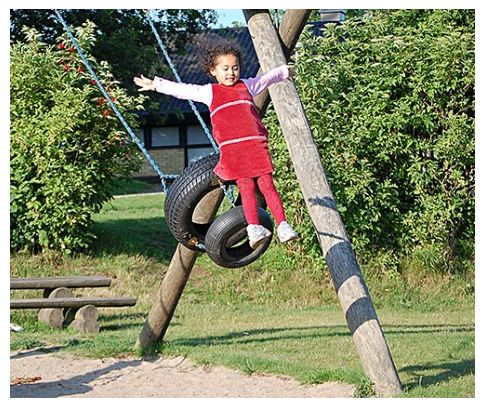

Image ID: 709373049_15b8b6457a.jpg
Ground Truth 1: A little girl plays with the tire swing at the playground .
Generated Caption: a boy in a red shirt is jumping off a swing


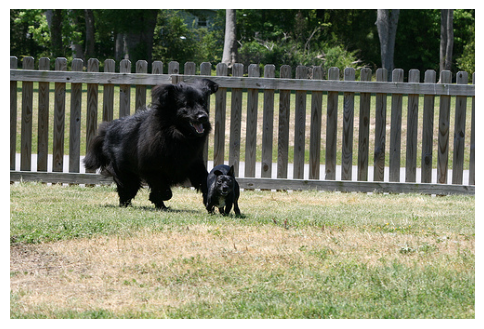

Image ID: 3476237185_9389c536a3.jpg
Ground Truth 1: A large and a small dog are standing beside each other in a fence .
Generated Caption: a dog is standing on a beach


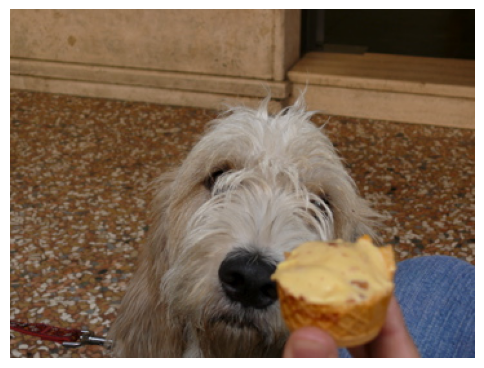

Image ID: 2909609550_070eea49b5.jpg
Ground Truth 1: A dog staring at the end of an ice cream cone .
Generated Caption: fountain


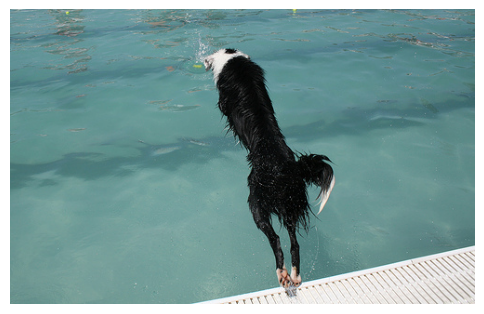

Image ID: 1350948838_fdebe4ff65.jpg
Ground Truth 1: A black and white dog jumping into a pool .
Generated Caption: a black and white dog is running through the water


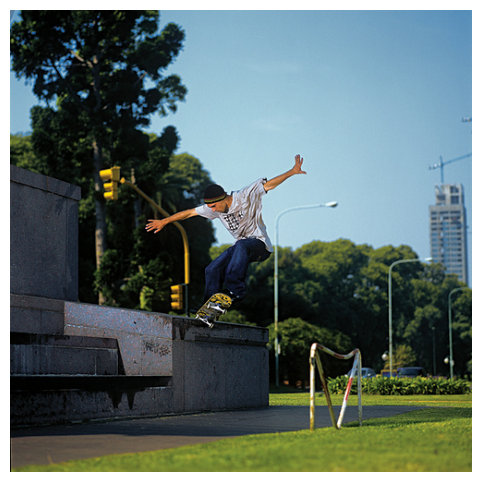

Image ID: 2968135512_51fbb56e3e.jpg
Ground Truth 1: A boy in a white t-shirt does skateboard tricks .
Generated Caption: a person in a red shirt is riding a bike

--- Visualizing Task 2 (LSTM) Test Examples ---


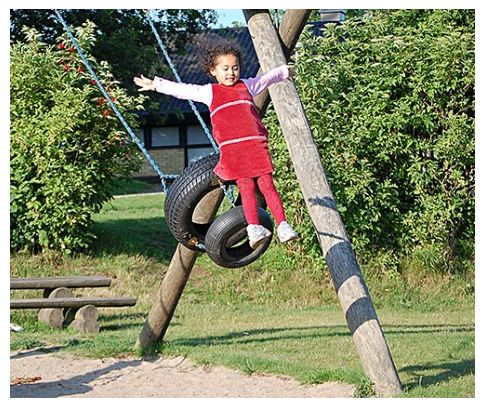

Image ID: 709373049_15b8b6457a.jpg
Ground Truth 1: A little girl plays with the tire swing at the playground .
Generated Caption: a boy in a blue shirt is climbing a rock


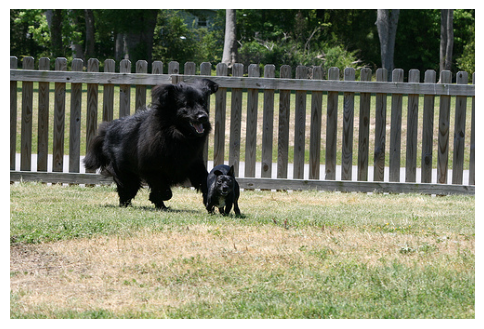

Image ID: 3476237185_9389c536a3.jpg
Ground Truth 1: A large and a small dog are standing beside each other in a fence .
Generated Caption: a black dog is running through a field


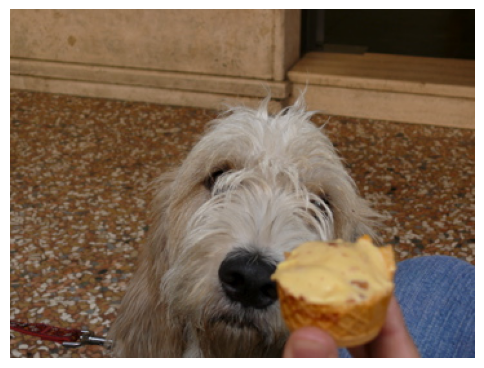

Image ID: 2909609550_070eea49b5.jpg
Ground Truth 1: A dog staring at the end of an ice cream cone .
Generated Caption: a dog is standing on a leash with a red leash


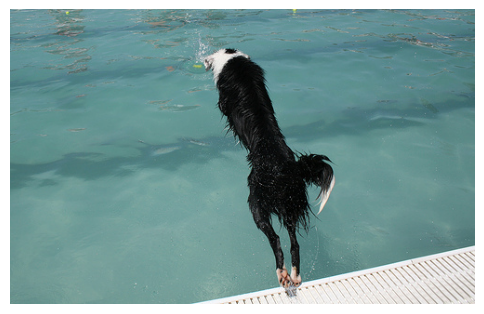

Image ID: 1350948838_fdebe4ff65.jpg
Ground Truth 1: A black and white dog jumping into a pool .
Generated Caption: a black and white dog is jumping into the water


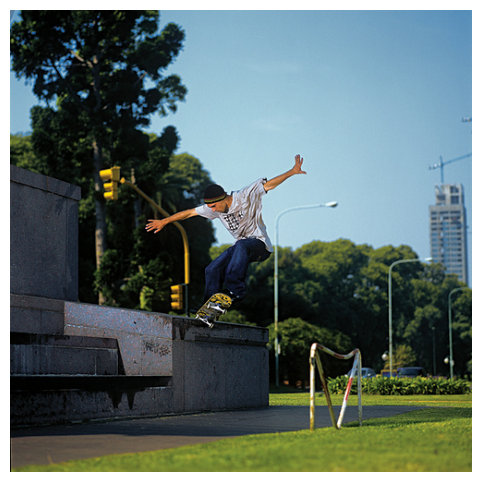

Image ID: 2968135512_51fbb56e3e.jpg
Ground Truth 1: A boy in a white t-shirt does skateboard tricks .
Generated Caption: a man is doing a trick on a bicycle


In [ ]:
def show_examples_with_images(encoder, decoder, data_loader, num_examples=5):
    encoder.eval()
    decoder.eval()
    examples_shown = 0
    shown_image_ids = set()
    
    with torch.no_grad():
        for imgs, _, img_ids, _ in data_loader:
            img_id = img_ids[0]
            
            if img_id in shown_image_ids:
                continue
                
            shown_image_ids.add(img_id)
            
            imgs = imgs.to(device)
            features = encoder(imgs)
            
            # Generating caption
            predicted_words = decoder.generate_caption(features[0], vocab)
            if "<EOS>" in predicted_words:
                predicted_words = predicted_words[:predicted_words.index("<EOS>")]
            predicted_sentence = " ".join(predicted_words)
            
            # fetching image
            references = captions_dict[img_id]
            
            # loading original image
            img_path = os.path.join(IMAGES_DIR, img_id)
            original_img = Image.open(img_path).convert("RGB")
            
            plt.figure(figsize=(6, 6))
            plt.imshow(original_img)
            plt.axis('off')
            plt.show()
            
            print(f"Image ID: {img_id}")
            print(f"Ground Truth 1: {references[0]}")
            print(f"Generated Caption: {predicted_sentence}")
            print("="*60)
            
            examples_shown += 1
            if examples_shown >= num_examples:
                break

print("\n--- Visualizing Task 1 (RNN) Test Examples ---")
show_examples_with_images(encoder_rnn, decoder_rnn, test_loader, num_examples=5)

print("\n--- Visualizing Task 2 (LSTM) Test Examples ---")
show_examples_with_images(encoder_lstm, decoder_lstm, test_loader, num_examples=5)



--- Visualizing Task 1 (RNN) Train Examples ---


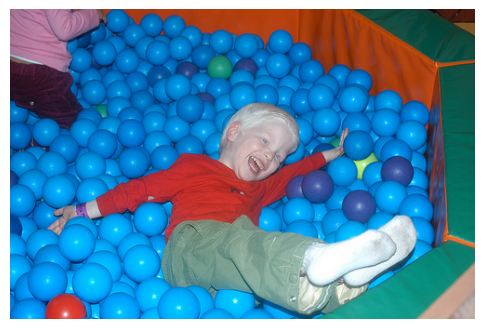

Image ID: 2265100168_175f8218af.jpg
Ground Truth 1: A laughing boy lies on a pit of blue balls .
Generated Caption: a boy is playing with a red and white toy


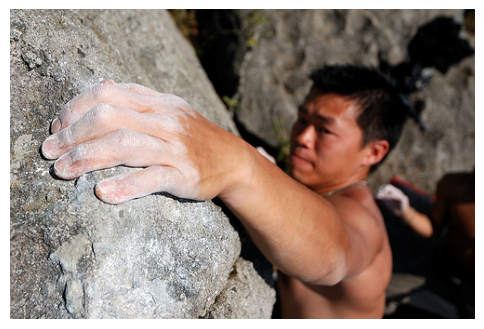

Image ID: 3099504809_565e17e49d.jpg
Ground Truth 1: A closeup of a shirtless man rock climbing .
Generated Caption: a man in a red shirt is rock climbing


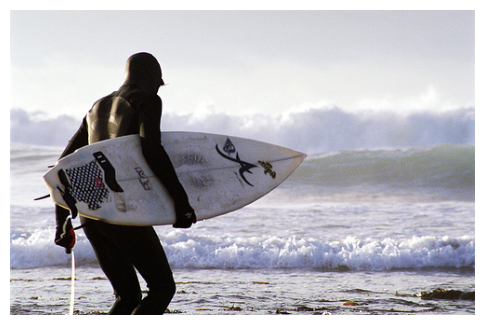

Image ID: 72964268_d532bb8ec7.jpg
Ground Truth 1: A man in a wetsuit with a surfboard walks along a beach
Generated Caption: a man in a blue jacket is jumping into the water


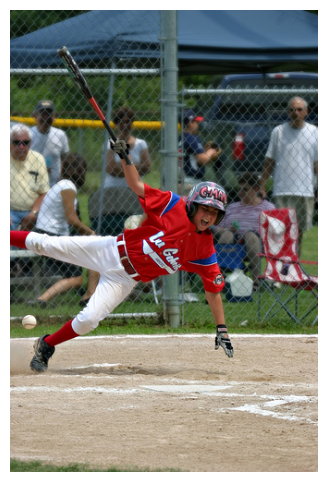

Image ID: 2662262499_3cdf49cedd.jpg
Ground Truth 1: A baseball hitter holding a bat falling down .
Generated Caption: a baseball player in a red uniform is running through the grass


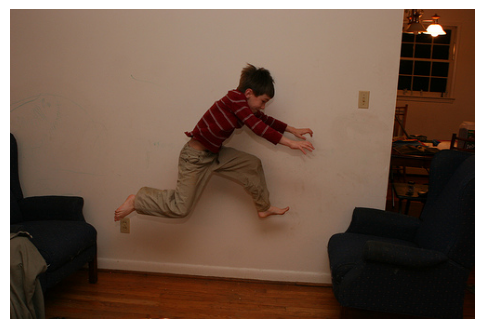

Image ID: 2286823363_7d554ea740.jpg
Ground Truth 1: A little boy jumping from one chair to another .
Generated Caption: a young boy is playing with a red and white

--- Visualizing Task 2 (LSTM) Train Examples ---


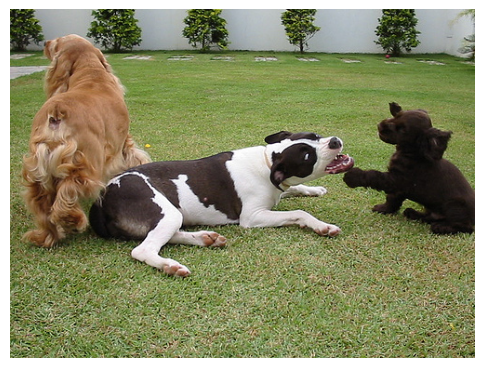

Image ID: 2257798999_d9d1b9a45a.jpg
Ground Truth 1: As the brown dog looks the other way , a large black and white dog plays with a smaller black dog .
Generated Caption: three dogs are playing in a field


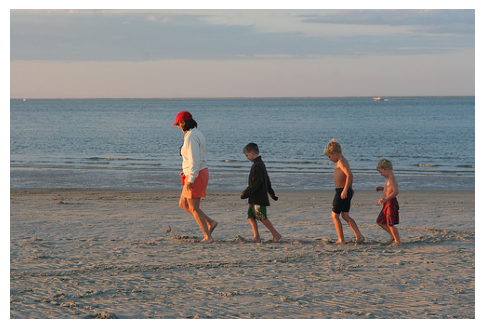

Image ID: 716597900_b72c58362c.jpg
Ground Truth 1: An adult and three children walk along the beach .
Generated Caption: a group of people are standing in the water with a stick in his mouth


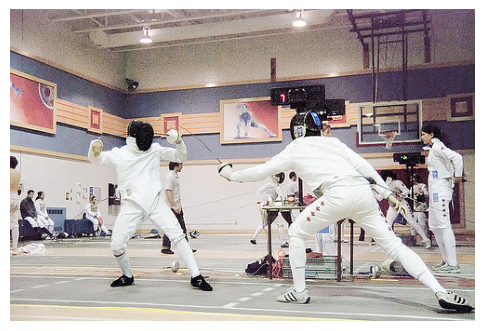

Image ID: 3262386960_14f5d857db.jpg
Ground Truth 1: A few players show off their jousting skills in a gym .
Generated Caption: two men in red uniforms are playing a game of a crowd of people


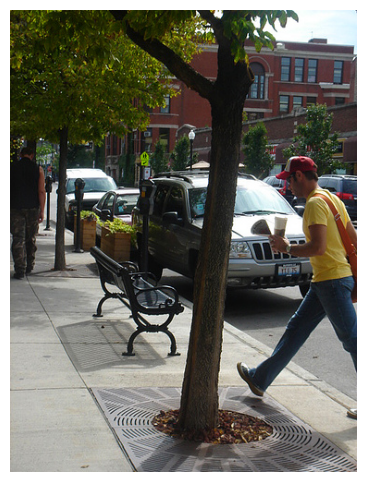

Image ID: 246901891_4c4ea49c3a.jpg
Ground Truth 1: A man in a yellow shirt walks past a tree on the sidewalk .
Generated Caption: a man is standing next to a <UNK>


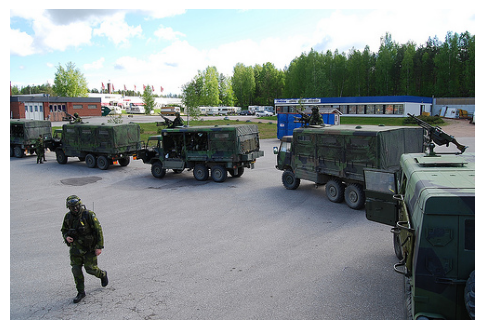

Image ID: 3566225740_375fc15dde.jpg
Ground Truth 1: A convoy of military trucks are lined up in a lot .
Generated Caption: a group of people walking down the street


In [16]:
print("\n--- Visualizing Task 1 (RNN) Train Examples ---")
show_examples_with_images(encoder_rnn, decoder_rnn, train_loader, num_examples=5)

print("\n--- Visualizing Task 2 (LSTM) Train Examples ---")
show_examples_with_images(encoder_lstm, decoder_lstm, train_loader, num_examples=5)

In [17]:
import pandas as pd

def print_bleu_report(encoder, decoder, data_loader, model_name):
    print(f"Calculating BLEU scores for {model_name}... (This may take a minute)")
    scores = calculate_bleu(encoder, decoder, data_loader)
    
    # Format nicely for the report
    df = pd.DataFrame({
        'Metric': ['BLEU@1', 'BLEU@2', 'BLEU@3', 'BLEU@4'],
        'Score': [
            round(scores[1], 4), 
            round(scores[2], 4), 
            round(scores[3], 4), 
            round(scores[4], 4)
        ]
    })
    print(f"\n=== {model_name} Final Metrics ===")
    print(df.to_string(index=False))
    print("===================================\n")

# Run Evaluation for Task 1 (RNN)
print_bleu_report(encoder_rnn, decoder_rnn, test_loader, "Task 1 (VGGNet + RNN)")

# Run Evaluation for Task 2 (LSTM)
print_bleu_report(encoder_lstm, decoder_lstm, test_loader, "Task 2 (VGGNet + LSTM)")


Calculating BLEU scores for Task 1 (VGGNet + RNN)... (This may take a minute)

=== Task 1 (VGGNet + RNN) Final Metrics ===
Metric  Score
BLEU@1 0.4698
BLEU@2 0.2848
BLEU@3 0.1820
BLEU@4 0.1215

Calculating BLEU scores for Task 2 (VGGNet + LSTM)... (This may take a minute)

=== Task 2 (VGGNet + LSTM) Final Metrics ===
Metric  Score
BLEU@1 0.5088
BLEU@2 0.3121
BLEU@3 0.2008
BLEU@4 0.1346

